prepare graphs for the article out of Salma's thesis

In [11]:
import re
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
# ============================================================
# 0. ANALYSIS-PERIOD DENOMINATORS
# ============================================================

# These values must match the filters used to create the temperature summary:
# All hours: 8,760 annual hours.
# Office hours: weekdays, 08:00-16:00 inclusive = 2,349 hours in 2026.
# School-occupied hours: the defined school calendar and exclusions = 1,611 hours.

ALL_HOURS_COUNT = 8760
OFFICE_HOURS_COUNT = 2349
SCHOOL_OCCUPIED_HOURS_COUNT = 1611


In [13]:
# ============================================================
# 1. LOAD DATA AND CLEAN COLUMN NAMES
# ============================================================

df = pd.read_excel('Master Data.xlsx')


def clean_column_name(name):
    """Convert Excel headings to consistent lowercase snake_case names."""
    name = str(name).replace("\xa0", " ").replace("\n", " ").strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return re.sub(r"_+", "_", name).strip("_")


df.columns = [clean_column_name(col) for col in df.columns]

print("Available columns after cleaning:")
print(df.columns.tolist())


def resolve_column(label, *candidates):
    """Return the first available candidate name or report a clear error."""
    cleaned_candidates = [clean_column_name(candidate) for candidate in candidates]

    for candidate in cleaned_candidates:
        if candidate in df.columns:
            return candidate

    raise KeyError(
        f"Missing column for '{label}'. Expected one of: {cleaned_candidates}"
    )


# ============================================================
# 4. RESOLVE THE NEW HEADINGS
# ============================================================

location_col = resolve_column("Location", "Location")
case_col = resolve_column("Case ID", "Case ID")

hours_26_all_col = resolve_column(
    "Hours above 26 degrees - all hours",
    "Hours above 26 degrees all hours",
    "Hours above 26 all hours",
)

hours_26_office_col = resolve_column(
    "Hours above 26 degrees - office hours",
    "Hours above 26 degrees office hours",
    "Hours above 26 office hours",
)

hours_26_school_col = resolve_column(
    "Hours above 26 degrees - school-occupied hours",
    "Hours above 26 degrees school occupied hours",
    "Hours above 26 school occupied",
    "Hours above 26 school occupied hours",
)

degree_26_school_col = resolve_column(
    "Degree-hours above 26 degrees - school-occupied hours",
    "Degree Hours Above 26 degrees school occupied hours",
    "Degree hours above 26 school occupied",
    "Degree hours above 26 school occupied hours",
)

vent_col = resolve_column(
    "Ventilation rate",
    "Ventilation Rate (L/s/person)",
    "Ventilation lps person",
)

wfr_col = resolve_column(
    "Window-to-floor ratio",
    "Window to Floor Ratio",
    "Window to floor ratio WFR",
)

orientation_col = resolve_column(
    "Building orientation",
    "Building Orientation",
)

wall_u_col = resolve_column(
    "Wall thermal transmittance",
    "Wall Thermal Transmittance",
    "Wall U Value",
)

roof_u_col = resolve_column(
    "Roof thermal transmittance",
    "Roof Thermal Transmittance",
    "Roof U Value",
)

window_u_col = resolve_column(
    "Window thermal transmittance",
    "Window Thermal Transmittance",
    "Window U Value",
)

g_col = resolve_column(
    "Solar heat gain coefficient",
    "SHGC",
    "Solar Heat Gain Coefficient",
)

floor_col = resolve_column("Floor", "Floor")

# The code accepts both the recommended headings ending in "With Ventilation"
# and the original headings without that ending. In both cases, these are
# interpreted as the ventilated results.

cat1_with_col = resolve_column(
    "Category I exceedance hours with ventilation",
    "Hours exceeding the Category I upper comfort limit With Ventilation",
    "Hours exceeding the Category I upper comfort limit",
)

cat2_with_col = resolve_column(
    "Category II exceedance hours with ventilation",
    "Hours exceeding the Category II upper comfort limit With Ventilation",
    "Hours exceeding the Category II upper comfort limit",
)

cat3_with_col = resolve_column(
    "Category III exceedance hours with ventilation",
    "Hours exceeding the Category III upper comfort limit With Ventilation",
    "Hours exceeding the Category III upper comfort limit",
)

overheating_with_col = resolve_column(
    "Overheating with ventilation",
    "Overheating With Ventilation",
    "Overheating",
)

cat1_without_col = resolve_column(
    "Category I exceedance hours without ventilation",
    "Hours exceeding the Category I upper comfort limit Without Ventilation",
)

cat2_without_col = resolve_column(
    "Category II exceedance hours without ventilation",
    "Hours exceeding the Category II upper comfort limit Without Ventilation",
)

cat3_without_col = resolve_column(
    "Category III exceedance hours without ventilation",
    "Hours exceeding the Category III upper comfort limit Without Ventilation",
)

overheating_without_col = resolve_column(
    "Overheating without ventilation",
    "Overheating Without Ventilation",
)

df.head()

Available columns after cleaning:
['location', 'case_id', 'tmean_all_hours', 'tmax_all_hours', 'tmin_all_hours', 'hours_above_26_degrees_all_hours', 'degree_hours_above_26_all_hours', 'tmean_office_hours', 'tmax_office_hours', 'tmin_office_hours', 'hours_above_26_degrees_office_hours', 'degree_hours_above_26_degrees_office_hours', 'tmean_school_occupied_hours', 'tmax_school_occupied_hours', 'tmin_school_occupied_hours', 'hours_above_26_degrees_school_occupied_hours', 'degree_hours_above_26_degrees_school_occupied_hours', 'ventilation_rate_l_s_person', 'window_to_floor_ratio', 'building_orientation', 'wall_thermal_transmittance', 'roof_thermal_transmittance', 'window_thermal_transmittance', 'shgc', 'floor', 'hours_exceeding_the_category_i_upper_comfort_limit_with_ventilation', 'hours_exceeding_the_category_ii_upper_comfort_limit_with_ventilation', 'hours_exceeding_the_category_iii_upper_comfort_limit_with_ventilation', 'overheating', 'hours_exceeding_the_category_i_upper_comfort_limit_w

,location,case_id,tmean_all_hours,tmax_all_hours,tmin_all_hours,hours_above_26_degrees_all_hours,degree_hours_above_26_all_hours,tmean_office_hours,tmax_office_hours,tmin_office_hours,...,floor,hours_exceeding_the_category_i_upper_comfort_limit_with_ventilation,hours_exceeding_the_category_ii_upper_comfort_limit_with_ventilation,hours_exceeding_the_category_iii_upper_comfort_limit_with_ventilation,overheating,hours_exceeding_the_category_i_upper_comfort_limit_without_ventilation,hours_exceeding_the_category_ii_upper_comfort_limit_without_ventilation,hours_exceeding_the_category_iii_upper_comfort_limit_without_ventilation,overheating_without_ventilation,unnamed_33
0,A,AGE-V1W1-R1O1G1,25.985616,37.074955,16.383045,4648,20493.011780,26.284692,36.924133,17.162548,...,G,15.853659,10.975610,0.000000,True,34.756098,28.780488,2.500000,True,N
1,A,AGE-V1W1-R1O1G2,26.739796,37.801754,17.155502,4932,24001.769037,26.990348,37.624210,17.946339,...,G,23.170732,17.743902,0.000000,True,40.853659,37.439024,6.036585,True,N
2,A,AGE-V1W1-R1O1G3,27.033459,37.979877,17.486206,5049,25411.044846,27.243674,37.799347,18.271648,...,G,25.000000,20.914634,0.121951,True,43.292683,39.451220,7.682927,True,N
3,A,AGE-V1W1-R1O1G4,27.893854,38.644073,18.571270,5357,29773.444918,28.037684,38.469181,19.307940,...,G,36.585366,31.341463,1.707317,True,51.829268,47.317073,14.634146,True,N
4,A,AGE-V1W1-R1O1G5,27.664200,38.334000,18.504543,5295,28390.106770,27.837889,38.178192,19.231028,...,G,34.146341,27.682927,0.731707,True,47.560976,45.304878,12.012195,True,N


In [14]:
# ============================================================
# 2. RESOLVE THE NEW HEADINGS
# ============================================================

location_col = resolve_column("Location", "Location")
case_col = resolve_column("Case ID", "Case ID")

hours_26_all_col = resolve_column(
    "Hours above 26 degrees - all hours",
    "Hours above 26 degrees all hours",
    "Hours above 26 all hours",
)

hours_26_office_col = resolve_column(
    "Hours above 26 degrees - office hours",
    "Hours above 26 degrees office hours",
    "Hours above 26 office hours",
)

hours_26_school_col = resolve_column(
    "Hours above 26 degrees - school-occupied hours",
    "Hours above 26 degrees school occupied hours",
    "Hours above 26 school occupied",
    "Hours above 26 school occupied hours",
)

degree_26_school_col = resolve_column(
    "Degree-hours above 26 degrees - school-occupied hours",
    "Degree Hours Above 26 degrees school occupied hours",
    "Degree hours above 26 school occupied",
    "Degree hours above 26 school occupied hours",
)

vent_col = resolve_column(
    "Ventilation rate",
    "Ventilation Rate (L/s/person)",
    "Ventilation lps person",
)

wfr_col = resolve_column(
    "Window-to-floor ratio",
    "Window to Floor Ratio",
    "Window to floor ratio WFR",
)

orientation_col = resolve_column(
    "Building orientation",
    "Building Orientation",
)

wall_u_col = resolve_column(
    "Wall thermal transmittance",
    "Wall Thermal Transmittance",
    "Wall U Value",
)

roof_u_col = resolve_column(
    "Roof thermal transmittance",
    "Roof Thermal Transmittance",
    "Roof U Value",
)

window_u_col = resolve_column(
    "Window thermal transmittance",
    "Window Thermal Transmittance",
    "Window U Value",
)

g_col = resolve_column(
    "Solar heat gain coefficient",
    "SHGC",
    "Solar Heat Gain Coefficient",
)

floor_col = resolve_column("Floor", "Floor")

# The code accepts both the recommended headings ending in "With Ventilation"
# and the original headings without that ending. In both cases, these are
# interpreted as the ventilated results.

cat1_with_col = resolve_column(
    "Category I exceedance hours with ventilation",
    "Hours exceeding the Category I upper comfort limit With Ventilation",
    "Hours exceeding the Category I upper comfort limit",
)

cat2_with_col = resolve_column(
    "Category II exceedance hours with ventilation",
    "Hours exceeding the Category II upper comfort limit With Ventilation",
    "Hours exceeding the Category II upper comfort limit",
)

cat3_with_col = resolve_column(
    "Category III exceedance hours with ventilation",
    "Hours exceeding the Category III upper comfort limit With Ventilation",
    "Hours exceeding the Category III upper comfort limit",
)

overheating_with_col = resolve_column(
    "Overheating with ventilation",
    "Overheating With Ventilation",
    "Overheating",
)

cat1_without_col = resolve_column(
    "Category I exceedance hours without ventilation",
    "Hours exceeding the Category I upper comfort limit Without Ventilation",
)

cat2_without_col = resolve_column(
    "Category II exceedance hours without ventilation",
    "Hours exceeding the Category II upper comfort limit Without Ventilation",
)

cat3_without_col = resolve_column(
    "Category III exceedance hours without ventilation",
    "Hours exceeding the Category III upper comfort limit Without Ventilation",
)

overheating_without_col = resolve_column(
    "Overheating without ventilation",
    "Overheating Without Ventilation",
)

In [15]:
# ============================================================
# 3. CLEAN VALUES
# ============================================================

df[location_col] = df[location_col].astype(str).str.strip().str.title()

location_map = {
    "A": "A - Lampedusa",
    "B": "B - Palermo",
    "C": "C - Napoli",
    "D": "D - Roma",
    "E": "E - Milano",
    "F": "F - Cuneo",
    "Lampedusa": "A - Lampedusa",
    "Palermo": "B - Palermo",
    "Napoli": "C - Napoli",
    "Roma": "D - Roma",
    "Milano": "E - Milano",
    "Cuneo": "F - Cuneo",
}

df["climate_zone"] = df[location_col].map(location_map).fillna(df[location_col])
climate_col = "climate_zone"

original_floor = df[floor_col].copy()

floor_clean = df[floor_col].astype(str).str.strip().str.title()
df[floor_col] = floor_clean.map(
    {
        "G": "Ground",
        "M": "Middle",
        "T": "Top",
        "Ground": "Ground",
        "Middle": "Middle",
        "Top": "Top",
    }
)
df[floor_col] = df[floor_col].fillna(original_floor)


def convert_binary(series):
    """Convert common Boolean/yes-no/0-1 values to numeric 0 or 1."""
    text_values = series.astype(str).str.upper().str.strip()
    mapped = text_values.map(
        {
            "TRUE": 1,
            "FALSE": 0,
            "YES": 1,
            "NO": 0,
            "1": 1,
            "0": 0,
            "1.0": 1,
            "0.0": 0,
        }
    )

    numeric_values = pd.to_numeric(series, errors="coerce")
    numeric_values = numeric_values.where(numeric_values.isin([0, 1]))
    return mapped.fillna(numeric_values)


df["overheating_with_num"] = convert_binary(df[overheating_with_col])
df["overheating_without_num"] = convert_binary(df[overheating_without_col])

numeric_cols = [
    hours_26_all_col,
    hours_26_office_col,
    hours_26_school_col,
    degree_26_school_col,
    vent_col,
    wfr_col,
    orientation_col,
    wall_u_col,
    roof_u_col,
    window_u_col,
    g_col,
    cat1_with_col,
    cat2_with_col,
    cat3_with_col,
    cat1_without_col,
    cat2_without_col,
    cat3_without_col,
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

standard_climate_order = [
    "A - Lampedusa",
    "B - Palermo",
    "C - Napoli",
    "D - Roma",
    "E - Milano",
    "F - Cuneo",
]

present_climates = set(df[climate_col].dropna().unique())
climate_order = [
    climate for climate in standard_climate_order if climate in present_climates
]
climate_order += sorted(present_climates.difference(standard_climate_order))


# ============================================================
# 6. CALCULATE VENTILATION BENEFIT
# ============================================================

# Positive values mean ventilation reduced the number of exceedance hours.
# Negative values mean more exceedance hours occurred with ventilation.

df["cat_i_reduction_hours"] = df[cat1_without_col] - df[cat1_with_col]
df["cat_ii_reduction_hours"] = df[cat2_without_col] - df[cat2_with_col]
df["cat_iii_reduction_hours"] = df[cat3_without_col] - df[cat3_with_col]

reduction_cols = [
    "cat_i_reduction_hours",
    "cat_ii_reduction_hours",
    "cat_iii_reduction_hours",
]

In [16]:
# ============================================================
# 4. DATA-QUALITY CHECKS
# ============================================================

paired_cols = [
    cat1_with_col,
    cat2_with_col,
    cat3_with_col,
    cat1_without_col,
    cat2_without_col,
    cat3_without_col,
]

missing_pair_mask = df[paired_cols].isna().any(axis=1)

invalid_order_with = ~(
    (df[cat1_with_col] >= df[cat2_with_col])
    & (df[cat2_with_col] >= df[cat3_with_col])
)

invalid_order_without = ~(
    (df[cat1_without_col] >= df[cat2_without_col])
    & (df[cat2_without_col] >= df[cat3_without_col])
)

# Category I-III exceedance values are calculated for all annual hours,
# so their valid range is 0-8,760 hours.
invalid_range = pd.Series(False, index=df.index)
for col in paired_cols:
    invalid_range = invalid_range | (df[col] < 0) | (
        df[col] > ALL_HOURS_COUNT
    )

comfort_check_failures = df.loc[
    missing_pair_mask | invalid_order_with | invalid_order_without | invalid_range,
    [location_col, case_col, vent_col] + paired_cols,
].copy()

comfort_check_failures["missing_with_without_pair"] = missing_pair_mask.loc[
    comfort_check_failures.index
]
comfort_check_failures["invalid_category_order_with_ventilation"] = (
    invalid_order_with.loc[comfort_check_failures.index]
)
comfort_check_failures["invalid_category_order_without_ventilation"] = (
    invalid_order_without.loc[comfort_check_failures.index]
)
comfort_check_failures["outside_valid_annual_hour_range"] = invalid_range.loc[
    comfort_check_failures.index
]

if comfort_check_failures.empty:
    print("Comfort-limit checks passed.")
else:
    print(
        "Warning:",
        len(comfort_check_failures),
        "rows failed at least one comfort-limit check.",
    )

vent_balance_check = (
    df.groupby([climate_col, vent_col], dropna=False)
    .size()
    .reset_index(name="count_cases")
)

wall_thermal_transmittance
roof_thermal_transmittance
window_thermal_transmittance
ventilation_rate_l_s_person
degree_hours_above_26_degrees_school_occupied_hours

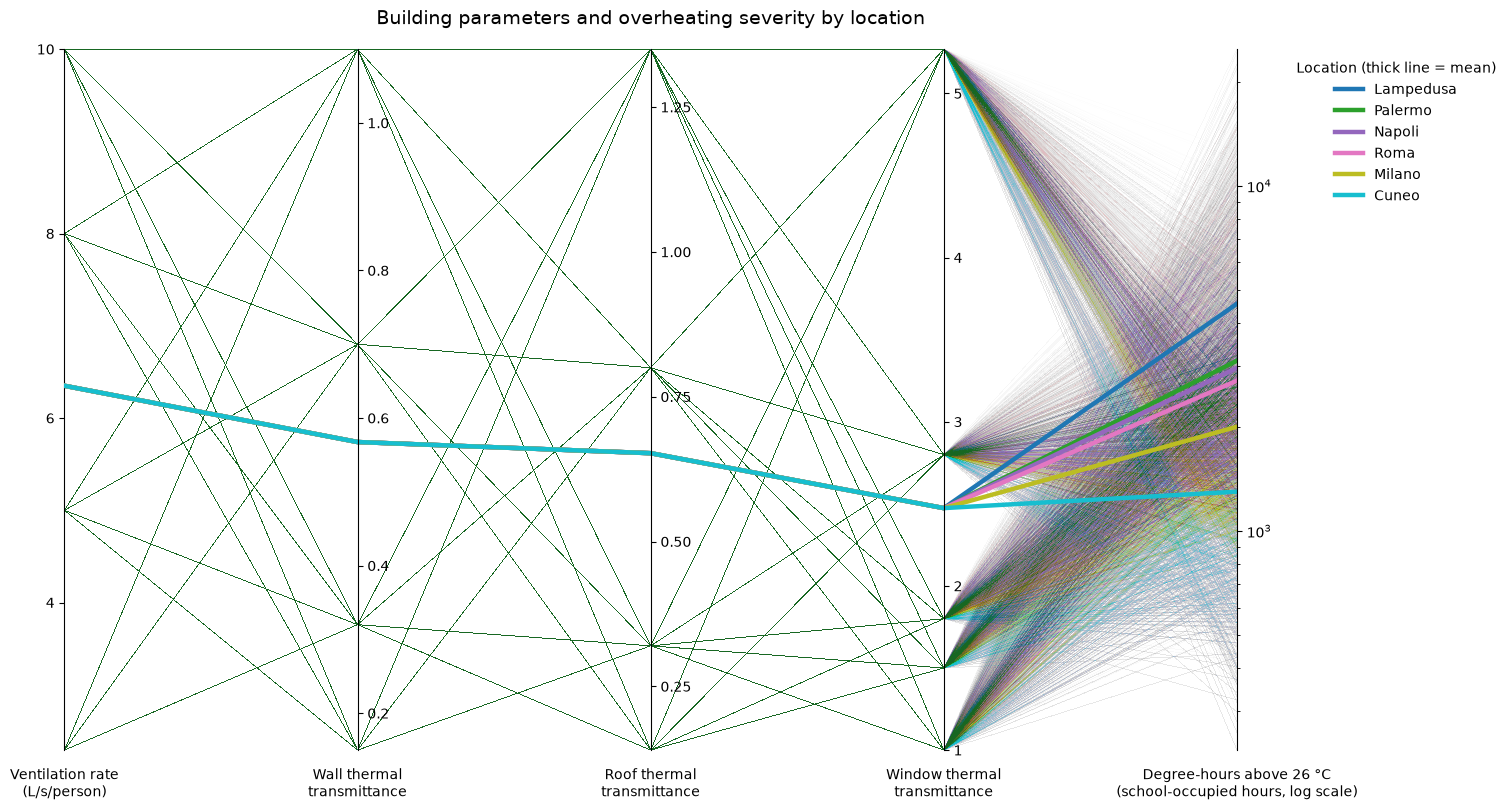

In [27]:
# ============================================================
# PARALLEL-COORDINATES PLOT BY LOCATION
# ============================================================

import numpy as np
from matplotlib.ticker import LogFormatterSciNotation, LogLocator, MaxNLocator

parallel_cols = [
    vent_col,
    wall_u_col,
    roof_u_col,
    window_u_col,
    degree_26_school_col,
]

axis_labels = [
    "Ventilation rate\n(L/s/person)",
    "Wall thermal\ntransmittance",
    "Roof thermal\ntransmittance",
    "Window thermal\ntransmittance",
    "Degree-hours above 26 °C\n(school-occupied hours, log scale)",
]

# Keep complete rows only so that every line crosses all five axes.
plot_data = df[[location_col, *parallel_cols]].dropna().copy()
if plot_data.empty:
    raise ValueError("No complete rows are available for the parallel-coordinates plot.")

log_axis_index = parallel_cols.index(degree_26_school_col)
if (plot_data[degree_26_school_col] <= 0).any():
    raise ValueError("The degree-hours axis requires positive values for a log scale.")

locations = sorted(plot_data[location_col].unique(), key=str)
location_legend_names = {
    "A": "Lampedusa",
    "B": "Palermo",
    "C": "Napoli",
    "D": "Roma",
    "E": "Milano",
    "F": "Cuneo",
}
x = np.arange(len(parallel_cols))

# Each variable keeps its own scale. Values are transformed only for drawing
# the connecting lines on the first axis.
raw_values = plot_data[parallel_cols].to_numpy(dtype=float)
axis_mins = np.nanmin(raw_values, axis=0)
axis_maxs = np.nanmax(raw_values, axis=0)
axis_mins[log_axis_index] = np.log10(axis_mins[log_axis_index])
axis_maxs[log_axis_index] = np.log10(axis_maxs[log_axis_index])

# Give any constant-valued axis a small visible range.
constant_axes = np.isclose(axis_mins, axis_maxs)
axis_mins[constant_axes] -= 0.5
axis_maxs[constant_axes] += 0.5
axis_ranges = axis_maxs - axis_mins

def to_first_axis_scale(values):
    """Map values from their own axes to the first axis for line drawing."""
    transformed_values = np.asarray(values, dtype=float).copy()
    transformed_values[..., log_axis_index] = np.log10(
        transformed_values[..., log_axis_index]
    )
    normalized = (transformed_values - axis_mins) / axis_ranges
    return normalized * axis_ranges[0] + axis_mins[0]

fig, host = plt.subplots(figsize=(15, 8), constrained_layout=True)
vertical_axes = [host] + [host.twinx() for _ in parallel_cols[1:]]

# Position one independently scaled vertical axis at each variable.
for i, axis in enumerate(vertical_axes):
    if i == log_axis_index:
        axis.set_yscale("log")
        axis.set_ylim(10 ** axis_mins[i], 10 ** axis_maxs[i])
        axis.yaxis.set_major_locator(LogLocator(base=10))
        axis.yaxis.set_major_formatter(LogFormatterSciNotation(base=10))
    else:
        axis.set_ylim(axis_mins[i], axis_maxs[i])
        axis.yaxis.set_major_locator(MaxNLocator(nbins=5))
    axis.grid(False)
    axis.spines["top"].set_visible(False)
    axis.spines["bottom"].set_visible(False)

    if i == 0:
        axis.spines["right"].set_visible(False)
        axis.yaxis.set_ticks_position("left")
    else:
        axis.patch.set_visible(False)
        axis.spines["left"].set_visible(False)
        axis.spines["right"].set_position(("axes", i / (len(parallel_cols) - 1)))
        axis.spines["right"].set_visible(True)
        axis.yaxis.set_ticks_position("right")

host.set_xlim(x[0], x[-1])
host.set_xticks(x)
host.set_xticklabels(axis_labels, fontsize=10)
host.tick_params(axis="x", length=0, pad=12)
host.set_title(
    "Building parameters and overheating severity by location",
    fontsize=14,
    pad=18,
)

# Use one colour per location. Thin transparent lines are individual cases;
# thick opaque lines are location averages.
location_colours = plt.cm.tab10(np.linspace(0, 1, max(len(locations), 1)))
for colour, location in zip(location_colours, locations):
    location_data = plot_data.loc[
        plot_data[location_col] == location, parallel_cols
    ]

    for case_values in to_first_axis_scale(location_data.to_numpy(dtype=float)):
        host.plot(x, case_values, color=colour, linewidth=0.05, alpha=0.05, zorder=1)

    mean_values = location_data.mean().to_numpy(dtype=float)
    host.plot(
        x,
        to_first_axis_scale(mean_values),
        color=colour,
        linewidth=3.2,
        alpha=1.0,
        label=location_legend_names.get(str(location), str(location)),
        zorder=3,
    )

host.legend(
    title="Location (thick line = mean)",
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    frameon=False,
)
plt.show()

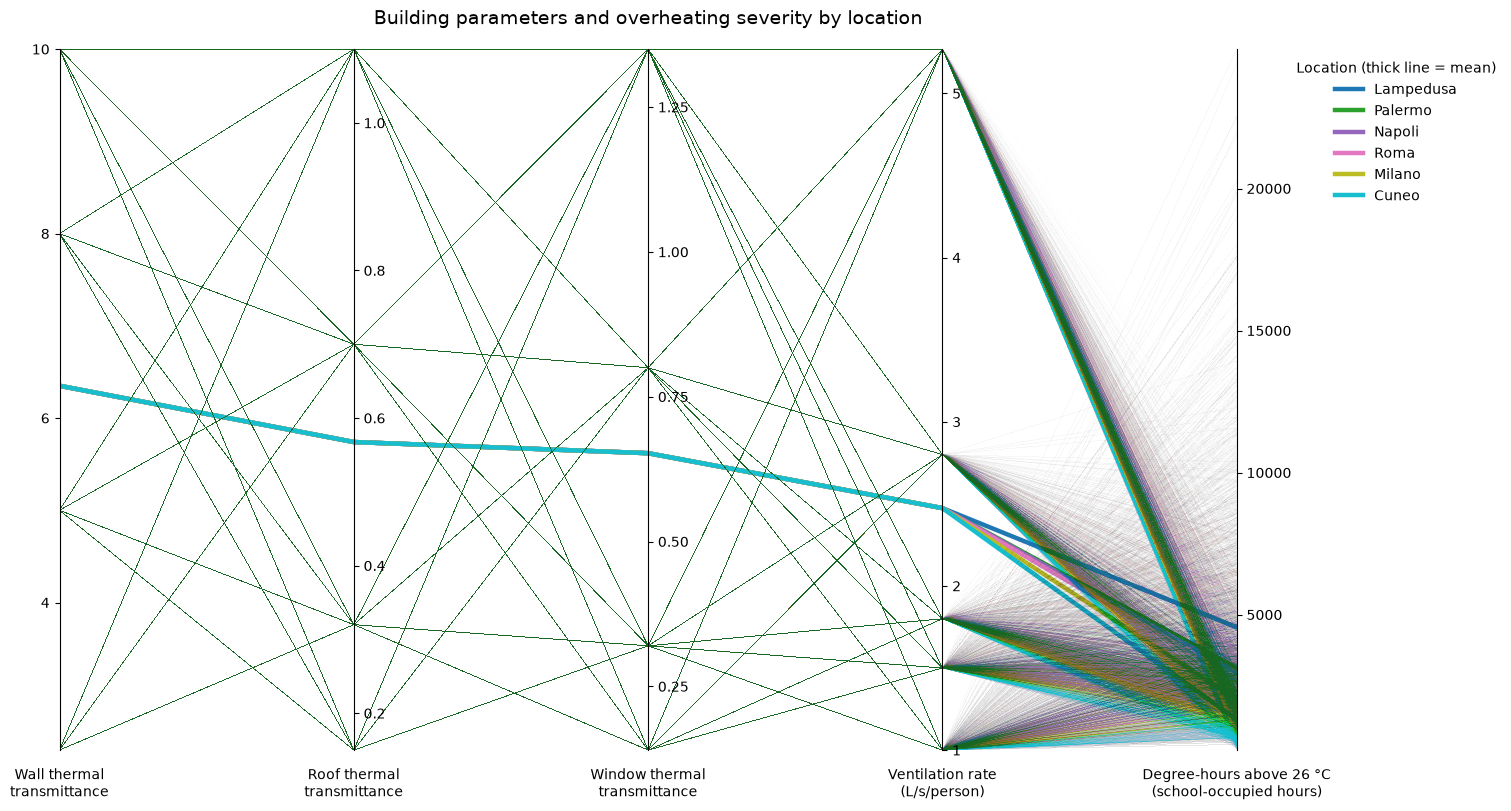

In [25]:
# ============================================================
# PARALLEL-COORDINATES PLOT BY LOCATION
# ============================================================

import numpy as np
from matplotlib.ticker import MaxNLocator

parallel_cols = [
    vent_col,
    wall_u_col,
    roof_u_col,
    window_u_col,
    degree_26_school_col,
]

axis_labels = [
    "Wall thermal\ntransmittance",
    "Roof thermal\ntransmittance",
    "Window thermal\ntransmittance",
    "Ventilation rate\n(L/s/person)",
    "Degree-hours above 26 °C\n(school-occupied hours)",
]

# Keep complete rows only so that every line crosses all five axes.
plot_data = df[[location_col, *parallel_cols]].dropna().copy()
if plot_data.empty:
    raise ValueError("No complete rows are available for the parallel-coordinates plot.")

locations = sorted(plot_data[location_col].unique(), key=str)
location_legend_names = {
    "A": "Lampedusa",
    "B": "Palermo",
    "C": "Napoli",
    "D": "Roma",
    "E": "Milano",
    "F": "Cuneo",
}
x = np.arange(len(parallel_cols))

# Each variable keeps its own scale. Values are transformed only for drawing
# the connecting lines on the first axis.
raw_values = plot_data[parallel_cols].to_numpy(dtype=float)
axis_mins = np.nanmin(raw_values, axis=0)
axis_maxs = np.nanmax(raw_values, axis=0)

# Give any constant-valued axis a small visible range.
constant_axes = np.isclose(axis_mins, axis_maxs)
axis_mins[constant_axes] -= 0.5
axis_maxs[constant_axes] += 0.5
axis_ranges = axis_maxs - axis_mins

def to_first_axis_scale(values):
    """Map values from their own axes to the first axis for line drawing."""
    values = np.asarray(values, dtype=float)
    normalized = (values - axis_mins) / axis_ranges
    return normalized * axis_ranges[0] + axis_mins[0]

fig, host = plt.subplots(figsize=(15, 8), constrained_layout=True)
vertical_axes = [host] + [host.twinx() for _ in parallel_cols[1:]]

# Position one independently scaled vertical axis at each variable.
for i, axis in enumerate(vertical_axes):
    axis.set_ylim(axis_mins[i], axis_maxs[i])
    axis.yaxis.set_major_locator(MaxNLocator(nbins=5))
    axis.grid(False)
    axis.spines["top"].set_visible(False)
    axis.spines["bottom"].set_visible(False)

    if i == 0:
        axis.spines["right"].set_visible(False)
        axis.yaxis.set_ticks_position("left")
    else:
        axis.patch.set_visible(False)
        axis.spines["left"].set_visible(False)
        axis.spines["right"].set_position(("axes", i / (len(parallel_cols) - 1)))
        axis.spines["right"].set_visible(True)
        axis.yaxis.set_ticks_position("right")

host.set_xlim(x[0], x[-1])
host.set_xticks(x)
host.set_xticklabels(axis_labels, fontsize=10)
host.tick_params(axis="x", length=0, pad=12)
host.set_title(
    "Building parameters and overheating severity by location",
    fontsize=14,
    pad=18,
)

# Use one colour per location. Thin transparent lines are individual cases;
# thick opaque lines are location averages.
location_colours = plt.cm.tab10(np.linspace(0, 1, max(len(locations), 1)))
for colour, location in zip(location_colours, locations):
    location_data = plot_data.loc[
        plot_data[location_col] == location, parallel_cols
    ]

    for case_values in to_first_axis_scale(location_data.to_numpy(dtype=float)):
        host.plot(x, case_values, color=colour, linewidth=0.05, alpha=0.05, zorder=3)

    mean_values = location_data.mean().to_numpy(dtype=float)
    host.plot(
        x,
        to_first_axis_scale(mean_values),
        color=colour,
        linewidth=3.2,
        alpha=1.0,
        label=location_legend_names.get(str(location), str(location)),
        zorder=1,
    )

host.legend(
    title="Location (thick line = mean)",
    bbox_to_anchor=(1.04, 1),
    loc="upper left",
    frameon=False,
)
plt.show()

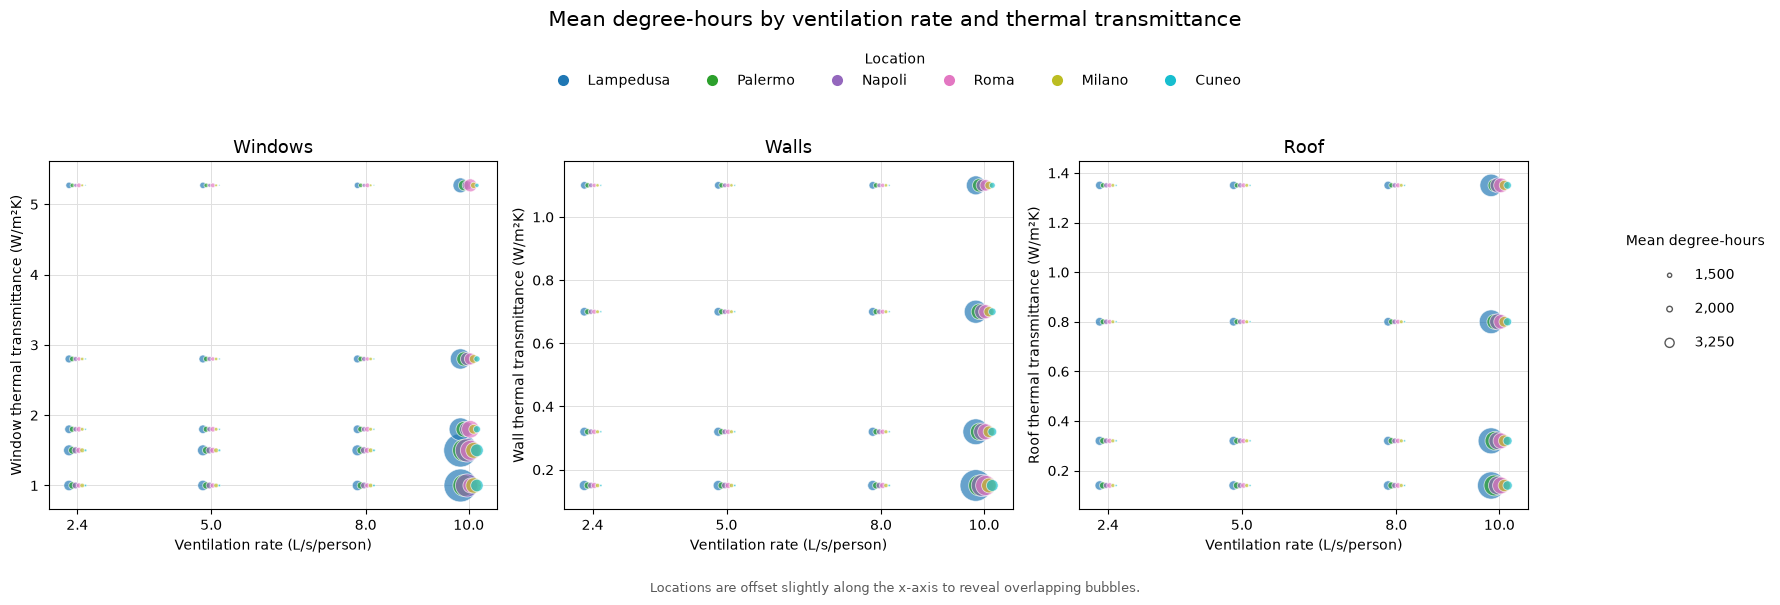

In [28]:
# ============================================================
# BUBBLE PLOTS: MEAN DEGREE-HOURS BY VENTILATION AND U-VALUE
# ============================================================

from matplotlib.lines import Line2D

subplot_specs = [
    (window_u_col, "Window thermal transmittance (W/m²K)", "Windows"),
    (wall_u_col, "Wall thermal transmittance (W/m²K)", "Walls"),
    (roof_u_col, "Roof thermal transmittance (W/m²K)", "Roof"),
]

bubble_columns = [column for column, _, _ in subplot_specs]
bubble_data = df[
    [location_col, vent_col, degree_26_school_col, *bubble_columns]
].dropna().copy()

if bubble_data.empty:
    raise ValueError("No complete rows are available for the bubble plots.")

locations = sorted(bubble_data[location_col].unique(), key=str)
location_names = {
    "A": "Lampedusa",
    "B": "Palermo",
    "C": "Napoli",
    "D": "Roma",
    "E": "Milano",
    "F": "Cuneo",
}
location_colours = dict(
    zip(locations, plt.cm.tab10(np.linspace(0, 1, max(len(locations), 1))))
)

# For each subplot, average degree-hours within every combination of
# location, ventilation rate, and the displayed thermal transmittance.
bubble_summaries = {}
for y_column, _, _ in subplot_specs:
    bubble_summaries[y_column] = (
        bubble_data.groupby(
            [location_col, vent_col, y_column],
            as_index=False,
            observed=True,
        )[degree_26_school_col]
        .mean()
        .rename(columns={degree_26_school_col: "mean_degree_hours"})
    )

all_mean_degree_hours = pd.concat(
    [summary["mean_degree_hours"] for summary in bubble_summaries.values()],
    ignore_index=True,
)
maximum_mean_degree_hours = all_mean_degree_hours.max()
if maximum_mean_degree_hours <= 0:
    raise ValueError("Mean degree-hours must be positive to scale the bubbles.")

# Matplotlib's s parameter is marker area in points squared. Squaring a
# radius that is proportional to degree-hours makes the visible disk radius
# proportional to the mean degree-hours, as requested.
MAXIMUM_RADIUS_POINTS = 24

def bubble_area(mean_degree_hours):
    radius_points = (
        np.asarray(mean_degree_hours, dtype=float)
        / maximum_mean_degree_hours
        * MAXIMUM_RADIUS_POINTS
    )
    return radius_points ** 2

# Locations share the same design grid, so a small horizontal dodge prevents
# bubbles at identical coordinates from hiding one another.
ventilation_levels = np.sort(bubble_data[vent_col].unique().astype(float))
if len(ventilation_levels) > 1:
    minimum_spacing = np.min(np.diff(ventilation_levels))
    maximum_dodge = 0.08 * minimum_spacing
else:
    maximum_dodge = 0.1

location_offsets = dict(
    zip(locations, np.linspace(-maximum_dodge, maximum_dodge, len(locations)))
)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True)

for axis, (y_column, y_label, subplot_title) in zip(axes, subplot_specs):
    summary = bubble_summaries[y_column]

    for location in locations:
        location_summary = summary.loc[summary[location_col] == location]
        axis.scatter(
            location_summary[vent_col] + location_offsets[location],
            location_summary[y_column],
            s=bubble_area(location_summary["mean_degree_hours"]),
            color=location_colours[location],
            alpha=0.68,
            edgecolors="white",
            linewidths=0.6,
            zorder=2,
        )

    axis.set_title(subplot_title, fontsize=13)
    axis.set_xlabel("Ventilation rate (L/s/person)")
    axis.set_ylabel(y_label)
    axis.set_xticks(ventilation_levels)
    axis.grid(True, color="0.88", linewidth=0.7, zorder=0)
    axis.margins(y=0.08)

fig.suptitle(
    "Mean degree-hours by ventilation rate and thermal transmittance",
    fontsize=15,
    y=0.99,
)

# One shared colour legend for all subplots.
location_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markersize=8,
        markerfacecolor=location_colours[location],
        markeredgecolor="none",
        label=location_names.get(str(location), str(location)),
    )
    for location in locations
]
fig.legend(
    handles=location_handles,
    title="Location",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=len(locations),
    frameon=False,
)

# A common size legend; bubble scaling is identical in all three subplots.
reference_values = np.unique(
    np.round(np.quantile(all_mean_degree_hours, [0.25, 0.50, 0.75]) / 250) * 250
)
reference_values = reference_values[reference_values > 0]
size_handles = [
    axes[-1].scatter(
        [],
        [],
        s=bubble_area(value),
        facecolors="none",
        edgecolors="0.35",
        linewidths=1.0,
    )
    for value in reference_values
]
fig.legend(
    handles=size_handles,
    labels=[f"{value:,.0f}" for value in reference_values],
    title="Mean degree-hours",
    loc="center right",
    bbox_to_anchor=(0.99, 0.52),
    frameon=False,
    labelspacing=1.4,
)

fig.text(
    0.5,
    0.02,
    "Locations are offset slightly along the x-axis to reveal overlapping bubbles.",
    ha="center",
    fontsize=9,
    color="0.35",
)
plt.tight_layout(rect=[0, 0.06, 0.86, 0.86])
plt.show()

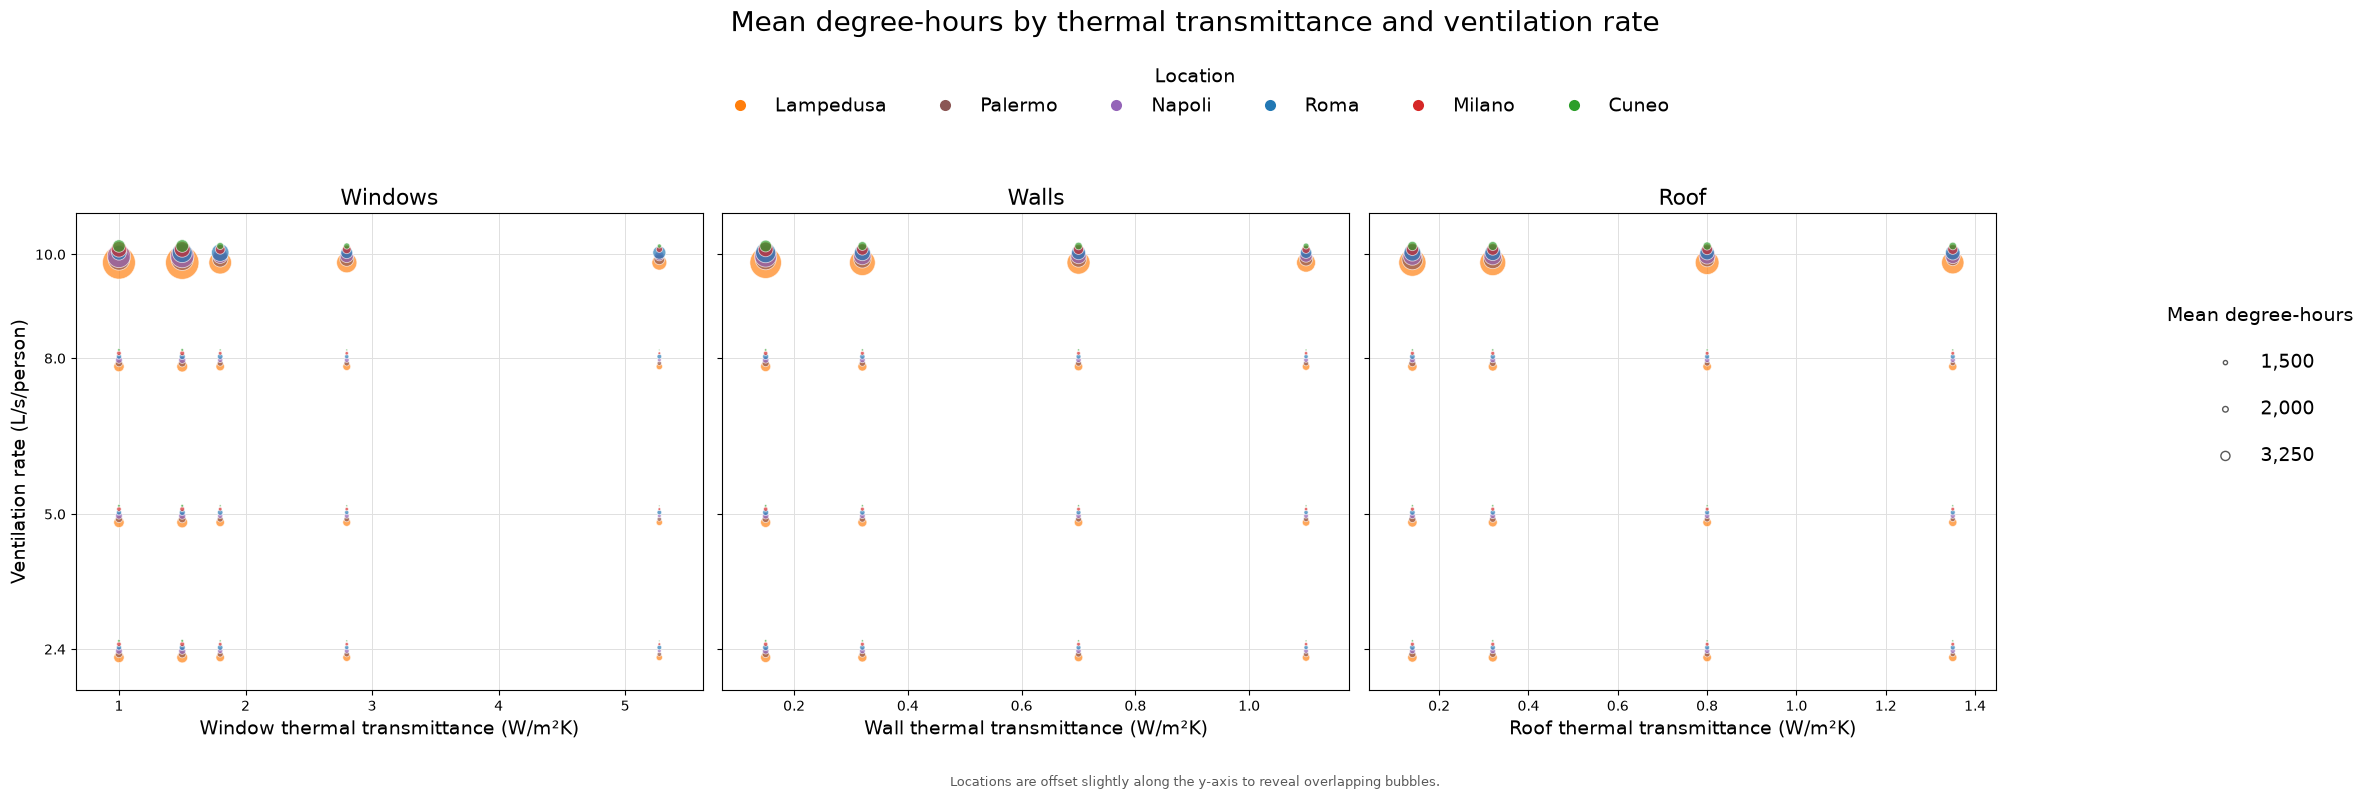

In [34]:
# ============================================================
# BUBBLE PLOTS WITH SWAPPED AXES
# ============================================================

location_colours = {
    "A": "#ff7e0c",  # Lampedusa - orange
    "B": "#8b5654",  # Palermo - brown
    "C": "#9464b8",  # Napoli - purple
    "D": "#2278b4",  # Roma - blue
    "E": "#d62726",  # Milano - red
    "F": "#2c9e2a",  # Cuneo - green
}

LEGEND_FONTSIZE = 14
LEGEND_TITLE_FONTSIZE = 14
AXIS_LABEL_FONTSIZE = 14
SUBPLOT_TITLE_FONTSIZE = 16
FIGURE_TITLE_FONTSIZE = 20

fig, axes = plt.subplots(1, 3, figsize=(24, 8), sharey=True)

for axis, (x_column, x_label, subplot_title) in zip(axes, subplot_specs):
    summary = bubble_summaries[x_column]

    for location in locations:
        location_summary = summary.loc[summary[location_col] == location]
        axis.scatter(
            location_summary[x_column],
            location_summary[vent_col] + location_offsets[location],
            s=bubble_area(location_summary["mean_degree_hours"]),
            color=location_colours[location],
            alpha=0.68,
            edgecolors="white",
            linewidths=0.6,
            zorder=2,
        )

    axis.set_title(subplot_title, fontsize=SUBPLOT_TITLE_FONTSIZE)
    axis.set_xlabel(x_label, fontsize=AXIS_LABEL_FONTSIZE)
    axis.set_yticks(ventilation_levels)
    axis.grid(True, color="0.88", linewidth=0.7, zorder=0)
    axis.margins(x=0.08, y=0.08)

axes[0].set_ylabel(
    "Ventilation rate (L/s/person)",
    fontsize=AXIS_LABEL_FONTSIZE,
)

fig.suptitle(
    "Mean degree-hours by thermal transmittance and ventilation rate",
    fontsize=FIGURE_TITLE_FONTSIZE,
    y=0.99,
)

location_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        markersize=8,
        markerfacecolor=location_colours[location],
        markeredgecolor="none",
        label=location_names.get(str(location), str(location)),
    )
    for location in locations
]
fig.legend(
    handles=location_handles,
    title="Location",
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=len(locations),
    frameon=False,
    fontsize=LEGEND_FONTSIZE,
    title_fontsize=LEGEND_TITLE_FONTSIZE,
)

size_handles = [
    axes[-1].scatter(
        [], [],
        s=bubble_area(value),
        facecolors="none",
        edgecolors="0.35",
        linewidths=1.0,
    )
    for value in reference_values
]
fig.legend(
    handles=size_handles,
    labels=[f"{value:,.0f}" for value in reference_values],
    title="Mean degree-hours",
    loc="center right",
    bbox_to_anchor=(0.99, 0.52),
    frameon=False,
    labelspacing=1.4,
    fontsize=LEGEND_FONTSIZE,
    title_fontsize=LEGEND_TITLE_FONTSIZE,
)

fig.text(
    0.5,
    0.02,
    "Locations are offset slightly along the y-axis to reveal overlapping bubbles.",
    ha="center",
    fontsize=9,
    color="0.35",
)
plt.tight_layout(rect=[0, 0.06, 0.84, 0.84])
plt.savefig("images/mean_degree_hours_bubble_plots_swapped_axes.png", dpi=900)
plt.show()